In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from IPython.display import display

pd.set_option("display.max_columns", 100)

In [2]:
DATA_DIR = Path("h-and-m-personalized-fashion-recommendations")

ARTICLES_PATH = DATA_DIR / "articles.csv"
CUSTOMERS_PATH = DATA_DIR / "customers.csv"
TRANSACTIONS_PATH = DATA_DIR / "transactions_train.csv"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

# Images may be inside DATA_DIR/images or another folder.
IMAGE_DIR = DATA_DIR / "images"

print("Dataset folder exists:", DATA_DIR.exists())
print("Image folder exists:", IMAGE_DIR.exists())

Dataset folder exists: True
Image folder exists: True


In [3]:
df_articles = pd.read_csv(ARTICLES_PATH)
df_customers = pd.read_csv(CUSTOMERS_PATH)
df_sample_submission = pd.read_csv(SUBMISSION_PATH)

print("Articles:", df_articles.shape)
print("Customers:", df_customers.shape)
print("Sample submission:", df_sample_submission.shape)

display(df_articles.head())

Articles: (105542, 25)
Customers: (1371980, 7)
Sample submission: (1371980, 2)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [4]:
df_transaction = pd.read_csv(
    TRANSACTIONS_PATH,
    usecols=["customer_id", "article_id", "t_dat", "price"],
    low_memory=False
)

print("Transactions:", df_transaction.shape)
display(df_transaction.head())

Transactions: (31788324, 4)


,t_dat,customer_id,article_id,price
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932


In [5]:
print("Column names:")
print(df_articles.columns.tolist())

print("\nDataset information:")
df_articles.info()

print("\nStatistical summary:")
display(df_articles.describe(include="all").T)

print("\nFirst 5 articles:")
display(df_articles.head())

Column names:
['article_id', 'product_code', 'prod_name', 'product_type_no', 'product_type_name', 'product_group_name', 'graphical_appearance_no', 'graphical_appearance_name', 'colour_group_code', 'colour_group_name', 'perceived_colour_value_id', 'perceived_colour_value_name', 'perceived_colour_master_id', 'perceived_colour_master_name', 'department_no', 'department_name', 'index_code', 'index_name', 'index_group_no', 'index_group_name', 'section_no', 'section_name', 'garment_group_no', 'garment_group_name', 'detail_desc']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   article_id                    105542 non-null  int64 
 1   product_code                  105542 non-null  int64 
 2   prod_name                     105542 non-null  object
 3   product_type_no               105542 n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
article_id,105542.0,NaN,NaN,NaN,698424569.096919,128462381.336161,108775015.0,616992501.0,702213001.5,796703001.75,959461001.0
product_code,105542.0,NaN,NaN,NaN,698424.563378,128462.384432,108775.0,616992.5,702213.0,796703.0,959461.0
prod_name,105542,45875,Dragonfly dress,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_type_no,105542.0,NaN,NaN,NaN,234.861875,75.049308,-1.0,252.0,259.0,272.0,762.0
product_type_name,105542,131,Trousers,11169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_group_name,105542,19,Garment Upper body,42741,NaN,NaN,NaN,NaN,NaN,NaN,NaN
graphical_appearance_no,105542.0,NaN,NaN,NaN,1009515.075723,22413.585778,-1.0,1010008.0,1010016.0,1010016.0,1010029.0
graphical_appearance_name,105542,30,Solid,49747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
colour_group_code,105542.0,NaN,NaN,NaN,32.233822,28.086154,-1.0,9.0,14.0,52.0,93.0
colour_group_name,105542,50,Black,22670,NaN,NaN,NaN,NaN,NaN,NaN,NaN



First 5 articles:


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [6]:
if "url" in df_articles.columns:
    display(df_articles[["url"]].head(10))
else:
    print("No 'url' column found.")
    print("Available columns:", df_articles.columns.tolist())

No 'url' column found.
Available columns: ['article_id', 'product_code', 'prod_name', 'product_type_no', 'product_type_name', 'product_group_name', 'graphical_appearance_no', 'graphical_appearance_name', 'colour_group_code', 'colour_group_name', 'perceived_colour_value_id', 'perceived_colour_value_name', 'perceived_colour_master_id', 'perceived_colour_master_name', 'department_no', 'department_name', 'index_code', 'index_name', 'index_group_no', 'index_group_name', 'section_no', 'section_name', 'garment_group_no', 'garment_group_name', 'detail_desc']


In [7]:
if not IMAGE_DIR.exists():
    print("Image folder not found at:", IMAGE_DIR)
    print("Check where you extracted the dataset.")
else:
    image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

    image_paths = [
        p for p in IMAGE_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print("Total images found:", len(image_paths))
    print("Sample image paths:")

    for path in image_paths[:10]:
        print(path)

Total images found: 105102
Sample image paths:
h-and-m-personalized-fashion-recommendations\images\010\0108775015.jpg
h-and-m-personalized-fashion-recommendations\images\010\0108775044.jpg
h-and-m-personalized-fashion-recommendations\images\010\0108775051.jpg
h-and-m-personalized-fashion-recommendations\images\011\0110065001.jpg
h-and-m-personalized-fashion-recommendations\images\011\0110065002.jpg
h-and-m-personalized-fashion-recommendations\images\011\0110065011.jpg
h-and-m-personalized-fashion-recommendations\images\011\0111565001.jpg
h-and-m-personalized-fashion-recommendations\images\011\0111565003.jpg
h-and-m-personalized-fashion-recommendations\images\011\0111586001.jpg
h-and-m-personalized-fashion-recommendations\images\011\0111593001.jpg


In [8]:
image_lookup = {
    path.stem: str(path)
    for path in image_paths
}

df_articles["article_id_str"] = (
    df_articles["article_id"].astype(str).str.zfill(10)
)

df_articles["image_path"] = (
    df_articles["article_id_str"].map(image_lookup)
)

print("Articles:", len(df_articles))
print("Articles with images:", df_articles["image_path"].notna().sum())
print("Articles without images:", df_articles["image_path"].isna().sum())

display(
    df_articles[
        ["article_id", "prod_name", "product_type_name", "image_path"]
    ].head(10)
)

Articles: 105542
Articles with images: 105100
Articles without images: 442


,article_id,prod_name,product_type_name,image_path
0,108775015,Strap top,Vest top,h-and-m-personalized-fashion-recommendations\i...
1,108775044,Strap top,Vest top,h-and-m-personalized-fashion-recommendations\i...
2,108775051,Strap top (1),Vest top,h-and-m-personalized-fashion-recommendations\i...
3,110065001,OP T-shirt (Idro),Bra,h-and-m-personalized-fashion-recommendations\i...
4,110065002,OP T-shirt (Idro),Bra,h-and-m-personalized-fashion-recommendations\i...
5,110065011,OP T-shirt (Idro),Bra,h-and-m-personalized-fashion-recommendations\i...
6,111565001,20 den 1p Stockings,Underwear Tights,h-and-m-personalized-fashion-recommendations\i...
7,111565003,20 den 1p Stockings,Socks,h-and-m-personalized-fashion-recommendations\i...
8,111586001,Shape Up 30 den 1p Tights,Leggings/Tights,h-and-m-personalized-fashion-recommendations\i...
9,111593001,Support 40 den 1p Tights,Underwear Tights,h-and-m-personalized-fashion-recommendations\i...


Article ID: 108775015
Product: Strap top


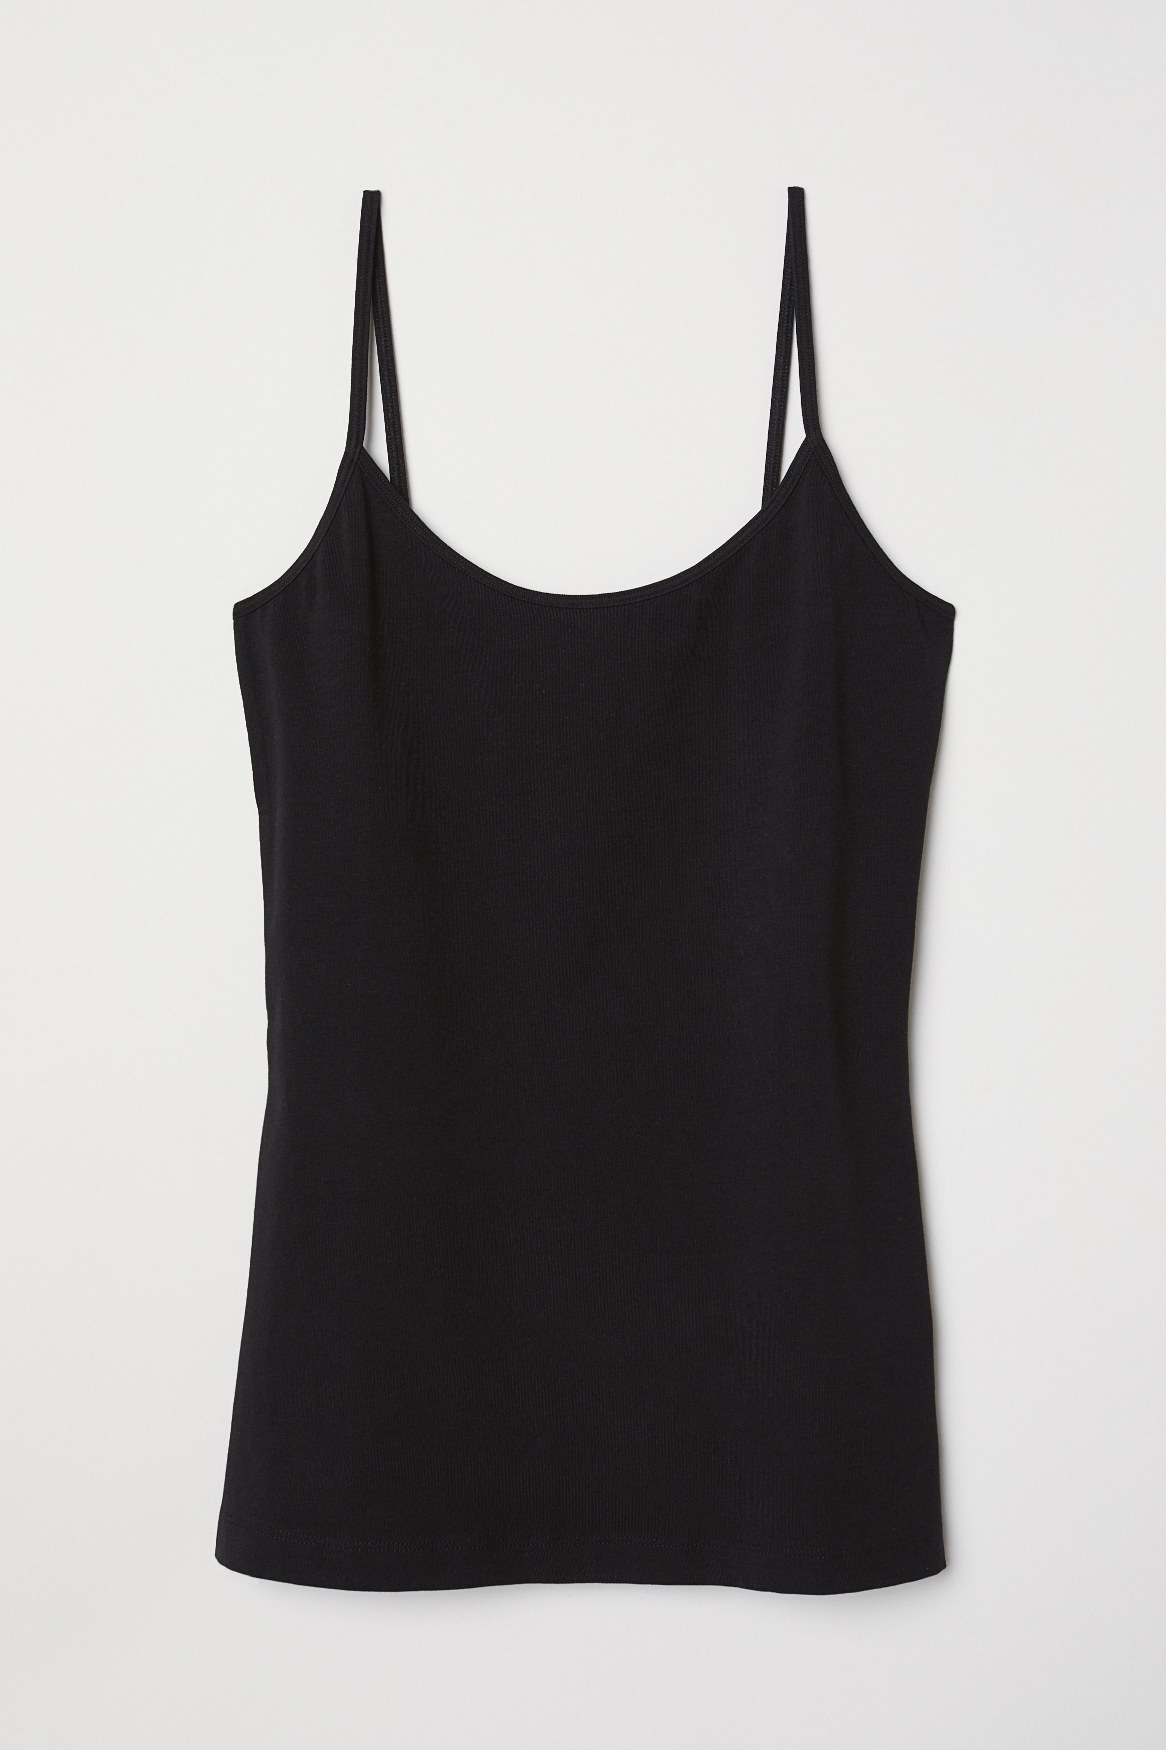

In [9]:
valid_images = df_articles[df_articles["image_path"].notna()]

if not valid_images.empty:
    row = valid_images.iloc[0]

    print("Article ID:", row["article_id"])
    print("Product:", row["prod_name"])

    with Image.open(row["image_path"]) as img:
        display(img.copy())
else:
    print("No matching images found. Check your image directory.")

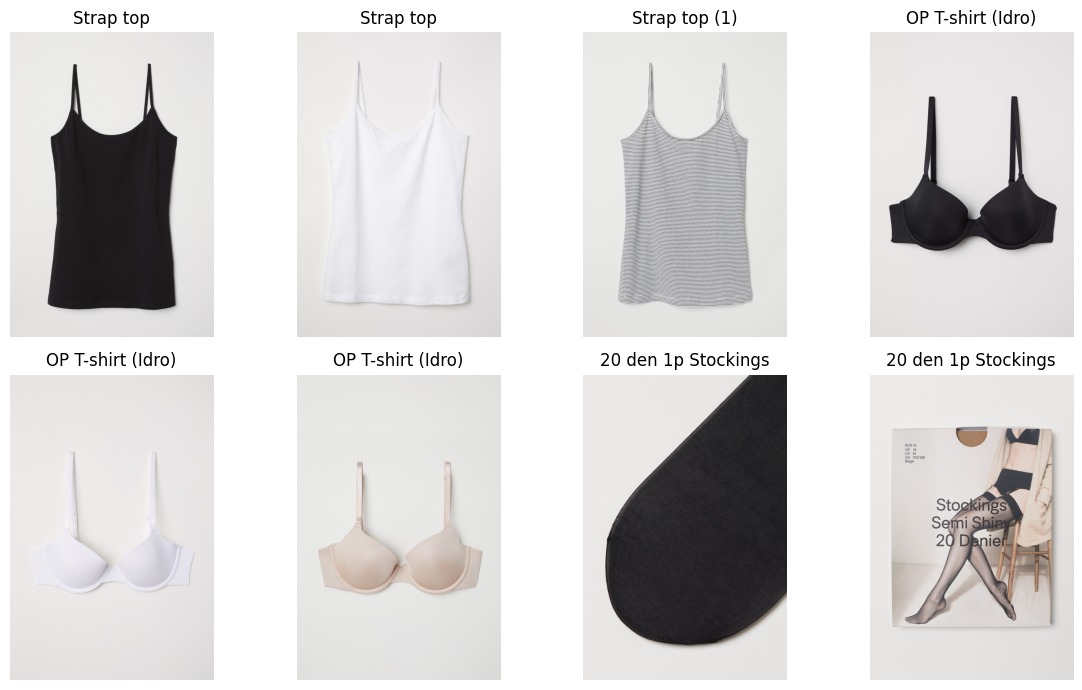

In [10]:
import matplotlib.pyplot as plt

sample = valid_images.head(8)

fig, axes = plt.subplots(2, 4, figsize=(12, 7))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):
    with Image.open(row["image_path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(str(row["prod_name"])[:30])
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()